In [12]:
import pandas as pd
import numpy as np

In [13]:
df = pd.read_csv("../data/clean_data/zh_regression_panel.csv")
df = df[(df["year"] >= 2011) & (df["year"] <= 2022)]
df = df.drop(columns="tertiary_share")
df = df.dropna()
df["log_median_income"] = np.log(df["median_income"])
df["log_population_density"] = np.log(df["population_density"])
print(df.shape)

(1677, 11)


In [14]:
#use model 3 regression layout
import statsmodels.formula.api as smf

formula = "turnout ~ foreigner_rate + social_assistance_rate + unemployment_rate + log_median_income + old_age_ratio + log_population_density"

model3 = smf.ols(formula + " + C(GDENR) + C(year)", data=df).fit(cov_type="cluster", cov_kwds={"groups": df["GDENR"]})
print(model3.params[["foreigner_rate", "social_assistance_rate", "unemployment_rate", "log_median_income", "old_age_ratio", "log_population_density"]].round(3))

foreigner_rate           -0.124
social_assistance_rate   -0.014
unemployment_rate        -0.015
log_median_income         9.412
old_age_ratio             0.109
log_population_density   -7.137
dtype: float64


In [15]:
# go through all the factors and apply the fucntion for vif, The loop starts at 1 because column 0 of X is the constant, which we skip
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

factors = ["foreigner_rate", "social_assistance_rate", "unemployment_rate", "log_median_income", "old_age_ratio", "log_population_density"]

X = sm.add_constant(df[factors])

vif_values = []
for i in range(1, len(factors) + 1):
    vif_values.append(variance_inflation_factor(X.values, i))

vif = pd.DataFrame({"variable": factors, "VIF": vif_values})
print(vif.round(2))


                 variable   VIF
0          foreigner_rate  3.50
1  social_assistance_rate  2.86
2       unemployment_rate  2.26
3       log_median_income  2.22
4           old_age_ratio  1.43
5  log_population_density  2.86


In [16]:
from statsmodels.nonparametric.smoothers_lowess import lowess

influence = model3.get_influence()

In [17]:
diag = pd.DataFrame({
    "fitted": model3.fittedvalues,
    "resid": model3.resid,
    "std_resid": influence.resid_studentized_internal,
    "leverage": influence.hat_matrix_diag,
    "cooks": influence.cooks_distance[0],
})

# drop municipalities with only one year (leverage = 1)
diag = diag[diag["leverage"] < 0.99]
print(diag.shape)

(1672, 5)


c:\Users\eneae\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\outliers_influence.py:961: RuntimeWarning: invalid value encountered in sqrt
  return self.resid / sigma / np.sqrt(1 - hii)


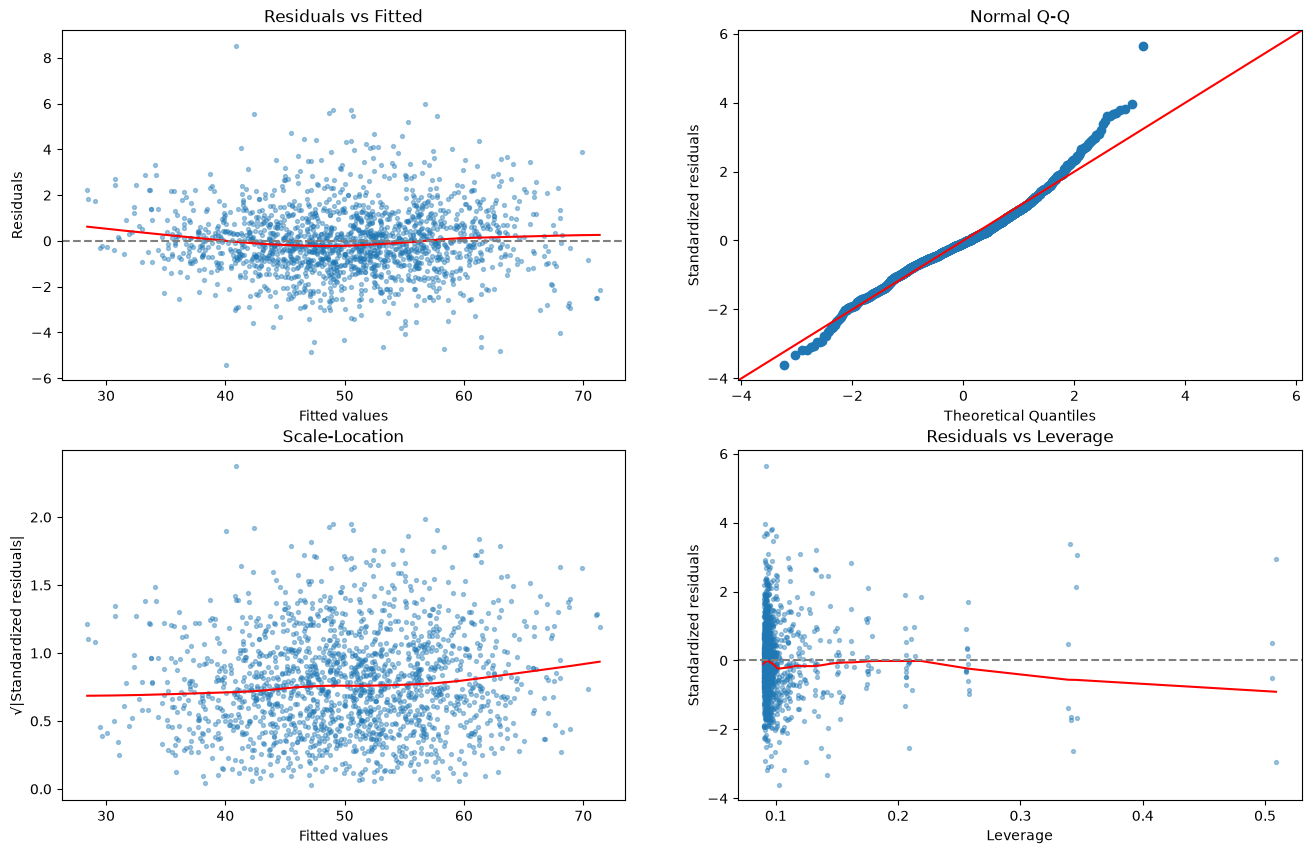

In [23]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Residuals vs Fitted -> linearity
ax = axes[0, 0]
ax.scatter(diag["fitted"], diag["resid"], s=8, alpha=0.4)
smooth = lowess(diag["resid"], diag["fitted"])
ax.plot(smooth[:, 0], smooth[:, 1], color="red")
ax.axhline(0, color="grey", linestyle="--")
ax.set_xlabel("Fitted values")
ax.set_ylabel("Residuals")
ax.set_title("Residuals vs Fitted")

# Normal Q-Q -> normality of residuals
ax = axes[0, 1]
sm.qqplot(diag["std_resid"], line="45", ax=ax)
ax.set_ylabel("Standardized residuals")
ax.set_title("Normal Q-Q")

# Scale-Location -> equal variance of residuals
ax = axes[1, 0]
sqrt_std_resid = np.sqrt(np.abs(diag["std_resid"]))
ax.scatter(diag["fitted"], sqrt_std_resid, s=8, alpha=0.4)
smooth = lowess(sqrt_std_resid, diag["fitted"])
ax.plot(smooth[:, 0], smooth[:, 1], color="red")
ax.set_xlabel("Fitted values")
ax.set_ylabel("√|Standardized residuals|")
ax.set_title("Scale-Location")

# Residuals vs Leverage -> influential observations
ax = axes[1, 1]
ax.scatter(diag["leverage"], diag["std_resid"], s=8, alpha=0.4)
smooth = lowess(diag["std_resid"], diag["leverage"])
ax.plot(smooth[:, 0], smooth[:, 1], color="red")
ax.axhline(0, color="grey", linestyle="--")
ax.set_xlabel("Leverage")
ax.set_ylabel("Standardized residuals")
ax.set_title("Residuals vs Leverage")

plt.show()

In [ ]:
print(diag["cooks"].max())
print((diag["cooks"] > 1).sum())

0.051616338552459326
0
